# SGI-7.13 — Wrong Storm, missing Thor

**Marvel Superstars**, week 7 (exercise 7.13, "Go nuts with your LLM"). Same 303 characters, same Wikipedia pages.

**The question.** When the text says a name, who do the machines think it is? The notebook follows that question in
two acts. In act I the name is on the page and the tools misread it: a static word vector, a contextual encoder, a page
encoder, three sentiment instruments and a named-entity tagger. In act II the name is on the page but the character
has no page of their own: Captain America, Thor and Iron Man are named all over the corpus and missing from the
network. We bring their articles in and watch the map, the clusterer and the search engine deal with them.

Every number in the post comes from this notebook through `stats.json`. Each section ends with a **Result** written
after reading the output. Two numbers are copied from our week-7 exercise notebooks (SGI-7.6 and SGI-7.8, not part of
this repository) and are marked where they enter.

In [1]:
import json, re, sys, urllib.parse, zipfile
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib, matplotlib.pyplot as plt, networkx as nx, numpy as np, pandas as pd, sklearn, spacy, torch
import gensim.downloader as api
import sentence_transformers, transformers, umap
from bertopic import BERTopic
from IPython.display import display
from scipy.stats import spearmanr
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.manifold import TSNE
from transformers import AutoModel, AutoTokenizer, pipeline
from umap import UMAP
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

for m in (np, pd, nx, sklearn, spacy, torch, transformers, sentence_transformers, umap, matplotlib):
    print(f"{m.__name__:22s} {m.__version__}")
print("python                ", sys.version.split()[0])

DATA1, DATA5, DATA7 = Path("../../Data/Week1"), Path("../../Data/Week5"), Path("../../Data/Week7")
FIG = Path("../../Figures/Week7"); FIG.mkdir(parents=True, exist_ok=True)
POST = Path("../../posts/week7/index.html")
STATS = {}
PAPER, INK, MID, RULE, ACC = "#EAE7E1", "#24211D", "#77716A", "#C9C3BA", "#E9B949"
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER, "font.size": 10.5,
                     "axes.edgecolor": MID, "axes.labelcolor": INK, "xtick.color": MID, "ytick.color": MID,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

W1026 14:01:03.398000 63782 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


numpy                  2.2.6
pandas                 3.0.6
networkx               3.7
sklearn                1.9.1
spacy                  3.8.16
torch                  2.14.1
transformers           5.20.2
sentence_transformers  6.2.0
umap                   0.5.12
matplotlib             3.11.2
python                 3.12.15


## 1. Load the network and the pages

The network is week 1's (303 characters, 1,784 links), the pages are the course's frozen snapshot of 2026-08-26.
Rows stay in week-1 order so the page vectors line up with the network.

In [2]:
nodes = pd.read_csv(DATA1 / "week1_nodes.tsv", sep="\t", comment="#", quoting=3).set_index("node_id")
edges = pd.read_csv(DATA1 / "week1_edges.tsv", sep="\t", comment="#", names=["source", "target"])
G = nx.DiGraph(); G.add_nodes_from(nodes.index); G.add_edges_from(edges.itertuples(index=False))
U = G.to_undirected()
with zipfile.ZipFile(DATA5 / "marvel_pages.zip") as z:
    pages = {urllib.parse.unquote(n.split("/")[-1][:-4]): z.read(n).decode("utf-8")
             for n in z.namelist() if n.endswith(".txt") and "README" not in n}
KEYS = list(nodes.index); N = len(KEYS); AT = {k: i for i, k in enumerate(KEYS)}
assert set(KEYS) == set(pages) and G.number_of_edges() == 1784
name = nodes["name"].replace({"Phoenix (Guardians of the Galaxy)": "Phoenix Force"})   # week 1's Wikidata label is wrong for this page
NAMES = [name[k] for k in KEYS]
texts = [pages[k] for k in KEYS]
BY = {n: i for i, n in enumerate(NAMES)}
print(f"{N} pages, {G.number_of_edges():,} links")

303 pages, 1,784 links


# Act I · Names that are there, misread

## 2. One vector for Storm

GloVe (trained on Wikipedia and news, 100 dimensions) is a **static** embedding: one vector per word type. BERT
(`bert-base-uncased`) is **contextual**: it computes a vector for each occurrence from the sentence around it. We take
the vector of *storm* in four sentences from Storm's own page and in four weather sentences we wrote, the course's
*bank* test with a Marvel word.

In [3]:
glove = api.load("glove-wiki-gigaword-100")
GLOVE_WORDS = ["storm", "venom", "widow", "cable", "stark", "sentry"]
glove_nn = {w: [[x, round(float(s), 2)] for x, s in glove.most_similar(w, topn=6)] for w in GLOVE_WORDS}
glove_pairs = {f"{a}|{b}": round(float(glove.similarity(a, b)), 2)
               for a, b in [("storm", "hurricane"), ("storm", "weather"), ("storm", "x-men"), ("storm", "mutant"), ("venom", "symbiote")]}
display(pd.DataFrame({w: [f"{x} {s:.2f}" for x, s in v] for w, v in glove_nn.items()}))
print(glove_pairs)

tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased").eval()


def bert_vec(word, sentence):
    enc = tok(sentence.lower(), return_tensors="pt")
    with torch.no_grad():
        h = bert(**enc).last_hidden_state[0]
    t = tok.convert_ids_to_tokens(enc["input_ids"][0])
    v = h[t.index(word)].numpy()
    return v / np.linalg.norm(v)


storm_sents = [s for s in re.split(r"(?<=[.!?])\s+", pages["Storm_(Marvel_Comics)"])
               if re.search(r"\bStorm\b", s) and 8 <= len(s.split()) <= 30]
WEATHER = ["A storm hit the coast last night and knocked out the power.",
           "The storm brought heavy rain and strong winds to the city.",
           "Farmers waited for the storm to pass before harvesting.",
           "The tropical storm grew into a hurricane over the warm sea."]
picked = storm_sents[:4]
V8 = np.array([bert_vec("storm", s) for s in picked + WEATHER]); C8 = V8 @ V8.T
mean_off = lambda M: float(M[np.triu_indices(len(M), 1)].mean())
Vall = np.array([bert_vec("storm", s) for s in storm_sents])
STATS["storm"] = dict(
    glove_nn=glove_nn, glove_pairs=glove_pairs, sentences=picked, weather=WEATHER, cos=np.round(C8, 2).tolist(),
    within_page=round(mean_off(C8[:4, :4]), 2), within_weather=round(mean_off(C8[4:, 4:]), 2),
    across=round(float(C8[:4, 4:].mean()), 2), n_page=len(storm_sents),
    all_to_weather=round(float((Vall @ V8[4:].T).mean()), 2), all_within=round(mean_off(Vall @ Vall.T), 2))
print({k: v for k, v in STATS["storm"].items() if k not in ("glove_nn", "sentences", "weather", "cos")})

,storm,venom,widow,cable,stark,sentry
0,hurricane 0.88,toxin 0.67,wife 0.81,network 0.81,grim 0.68,blimp 0.52
1,storms 0.82,scorpion 0.59,niece 0.78,networks 0.80,reminder 0.61,crouched 0.49
2,winds 0.81,symbiote 0.58,daughter 0.78,channel 0.77,backdrop 0.59,lookout 0.49
3,typhoon 0.76,poisonous 0.57,granddaughter 0.76,channels 0.75,sharp 0.59,sentries 0.49
4,cyclone 0.74,toxins 0.57,husband 0.75,tv 0.73,contrast 0.56,e-3 0.49
5,tropical 0.72,snake 0.56,mother 0.75,television 0.73,bleak 0.56,rifleman 0.49


{'storm|hurricane': 0.88, 'storm|weather': 0.67, 'storm|x-men': 0.2, 'storm|mutant': 0.18, 'venom|symbiote': 0.58}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'glove_pairs': {'storm|hurricane': 0.88, 'storm|weather': 0.67, 'storm|x-men': 0.2, 'storm|mutant': 0.18, 'venom|symbiote': 0.58}, 'within_page': 0.63, 'within_weather': 0.73, 'across': 0.28, 'n_page': 170, 'all_to_weather': 0.35, 'all_within': 0.69}


**Result.** GloVe's one *storm* sits next to *hurricane* (0.88) and far from *x-men* (0.20). BERT puts the
four Storm sentences close to each other and the weather sentences close to each other, with a much lower cosine
across. The same holds for all 170 sentences from her page that name her. GloVe also shows the other side of static
vectors: *venom* has *symbiote* among its neighbours, because Wikipedia and news mention the comic often enough.

## 3. The name leaks into the page vector

The page encoder is `all-MiniLM-L6-v2` with the course atlas's rule: pages cut into passages of at most 180 words along
sentence boundaries, every passage embedded, the page vector the mean of its passage vectors (the encoder reads at most
256 word pieces, and 302 of the 303 pages are longer). Then we replace a codename with the character's real name on
that one page, re-embed it, and see where its old neighbours went. Everything else stays fixed.

In [4]:
enc = SentenceTransformer("all-MiniLM-L6-v2")


def passages(text, max_words=180):
    out, cur, n = [], [], 0
    for s in re.split(r"(?<=[.!?])\s+", text):
        w = len(s.split())
        if cur and n + w > max_words:
            out.append(" ".join(cur)); cur, n = [], 0
        cur.append(s); n += w
    if cur:
        out.append(" ".join(cur))
    return out


def page_vec(text):
    v = enc.encode(passages(text), normalize_embeddings=True).mean(axis=0)
    return v / np.linalg.norm(v)


E = np.array([page_vec(t) for t in texts]); S = E @ E.T
assert [NAMES[j] for j in np.argsort(-S[BY["Storm (Marvel Comics)"]])[1:3]] == ["Emma Frost", "Jean Grey"]   # the course atlas
RENAMES = [("Black_Widow_(Natasha_Romanova)", "Black Widow", "Natasha Romanoff"),
           ("Black_Cat_(Marvel_Comics)", "Black Cat", "Felicia Hardy"),
           ("Black_Panther_(character)", "Black Panther", "T'Challa"),
           ("Storm_(Marvel_Comics)", "Storm", "Ororo Munroe")]
renames = []
for key, old, new in RENAMES:
    k = AT[key]
    v = page_vec(pages[key].replace(old, new)); row = E @ v; row[k] = -2
    before = [j for j in np.argsort(-S[k]) if j != k]; after = list(np.argsort(-row))
    rb, ra = {j: r + 1 for r, j in enumerate(before)}, {j: r + 1 for r, j in enumerate(after)}
    watch = [AT[w] for w in ("Black_Cat_(Marvel_Comics)", "Black_Widow_(Natasha_Romanova)", "Black_Marvel", "Human_Torch") if AT[w] != k]
    show = list(dict.fromkeys(before[:8] + after[:8] + watch))
    renames.append(dict(page=NAMES[k], old=old, new=new, swaps=pages[key].count(old), self_cos=round(float(E[k] @ v), 3),
                        rows=sorted([[NAMES[j], rb[j], ra[j], round(float(S[k, j]), 3), round(float(row[j]), 3)] for j in show],
                                    key=lambda r: r[1])))
for r in renames:
    print(f"{r['page']}: '{r['old']}' → '{r['new']}' ({r['swaps']} swaps)")
    display(pd.DataFrame(r["rows"], columns=["neighbour", "rank with codename", "rank with real name", "cos before", "cos after"]).head(12))
rank = lambda page, nb, i: next(x[i] for x in next(r for r in renames if r["page"] == page)["rows"] if x[0] == nb)
pca2 = PCA(n_components=2, random_state=42).fit(E)
STATS["rename"] = dict(rows=renames, pca_var=round(float(pca2.explained_variance_ratio_.sum()), 3),
                       bw_cat=[rank("Black Widow (Natasha Romanova)", "Black Cat (Marvel Comics)", 1), rank("Black Widow (Natasha Romanova)", "Black Cat (Marvel Comics)", 2)],
                       bw_marvel=[rank("Black Widow (Natasha Romanova)", "Black Marvel", 1), rank("Black Widow (Natasha Romanova)", "Black Marvel", 2)],
                       cat_bw=[rank("Black Cat (Marvel Comics)", "Black Widow (Natasha Romanova)", 1), rank("Black Cat (Marvel Comics)", "Black Widow (Natasha Romanova)", 2)],
                       bp_cat=[rank("Black Panther (character)", "Black Cat (Marvel Comics)", 1), rank("Black Panther (character)", "Black Cat (Marvel Comics)", 2)],
                       storm_torch=[rank("Storm (Marvel Comics)", "Human Torch", 1), rank("Storm (Marvel Comics)", "Human Torch", 2)],
                       storm_emma=[rank("Storm (Marvel Comics)", "Emma Frost", 1), rank("Storm (Marvel Comics)", "Emma Frost", 2)])
print({k: v for k, v in STATS["rename"].items() if k != "rows"})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Black Widow (Natasha Romanova): 'Black Widow' → 'Natasha Romanoff' (165 swaps)


,neighbour,rank with codename,rank with real name,cos before,cos after
0,Yelena Belova,1,2,0.719,0.664
1,Black Cat (Marvel Comics),2,19,0.699,0.573
2,Spider-Woman (Jessica Drew),3,1,0.649,0.667
3,Patsy Walker,4,17,0.637,0.576
4,Misty Knight,5,18,0.633,0.573
5,Spider-Bitch (Ashley Barton),6,12,0.629,0.587
6,Black Marvel,7,51,0.628,0.497
7,Scarlet Witch,8,3,0.622,0.663
8,Spider-Woman,10,5,0.618,0.617
9,She-Hulk,15,4,0.590,0.646


Black Cat (Marvel Comics): 'Black Cat' → 'Felicia Hardy' (180 swaps)


,neighbour,rank with codename,rank with real name,cos before,cos after
0,Black Widow (Natasha Romanova),1,12,0.699,0.644
1,Spider-Woman (Jessica Drew),2,1,0.671,0.709
2,Spider-Woman (Gwen Stacy),3,2,0.670,0.707
3,Spider-Bitch (Ashley Barton),4,3,0.667,0.701
4,Patsy Walker,5,10,0.667,0.650
5,Spider-Man,6,8,0.652,0.654
6,Spider-Woman,7,4,0.650,0.696
7,Spider-Man Noir,8,6,0.642,0.664
8,Spider-Girl,10,5,0.633,0.686
9,Janice Lincoln,15,7,0.599,0.660


Black Panther (character): 'Black Panther' → 'T'Challa' (161 swaps)


,neighbour,rank with codename,rank with real name,cos before,cos after
0,Shuri (character),1,1,0.793,0.789
1,Storm (Marvel Comics),2,6,0.643,0.588
2,Black Cat (Marvel Comics),3,20,0.637,0.535
3,Black Marvel,4,12,0.634,0.558
4,Luke Cage,5,7,0.625,0.578
5,Ravage 2099,6,2,0.600,0.626
6,Darkhawk,7,11,0.592,0.561
7,Shang-Chi,8,8,0.586,0.577
8,Black Widow (Natasha Romanova),11,68,0.577,0.487
9,Sentry (Robert Reynolds),12,3,0.574,0.593


Storm (Marvel Comics): 'Storm' → 'Ororo Munroe' (240 swaps)


,neighbour,rank with codename,rank with real name,cos before,cos after
0,Emma Frost,1,1,0.712,0.636
1,Jean Grey,2,3,0.701,0.620
2,Surge (Marvel Comics),3,2,0.679,0.623
3,Jubilee (character),4,5,0.664,0.605
4,Cyclops (Marvel Comics),5,9,0.655,0.569
5,Jean Grey (X-Men film series),6,8,0.651,0.570
6,Rachel Summers,7,10,0.644,0.566
7,Black Panther (character),8,6,0.643,0.577
8,Northstar (character),9,7,0.633,0.574
9,Wolverine (character),12,4,0.622,0.614


{'pca_var': 0.099, 'bw_cat': [2, 19], 'bw_marvel': [7, 51], 'cat_bw': [1, 12], 'bp_cat': [3, 20], 'storm_torch': [14, 74], 'storm_emma': [1, 1]}


**Result.** The word *Black* carries weight of its own. With her real name, Black Widow's page loses Black Cat and
Black Marvel as neighbours; Black Cat's page, renamed Felicia Hardy, loses Black Widow; Black Panther, renamed
T'Challa, loses Black Cat and Black Marvel (this reproduces SGI-7.2). Storm is the control: her X-Men neighbours survive
her real name, and the only page that falls far is Human Torch, whose real name is Johnny Storm. PCA's two axes
explain about a tenth of the variance, so none of this shows reliably on a 2D map; the ranks are computed in the
original 384 dimensions.

## 4. Names read as feelings

Three instruments from the week: the VADER lexicon (a word list with human ratings), a TF-IDF + logistic-regression
classifier (from SGI-7.6) and DistilBERT fine-tuned on movie reviews (SST-2). We put 19 codenames from the corpus into
three neutral sentence frames. Nothing in the frames is positive or negative; only the name changes.

In [5]:
vader = SentimentIntensityAnalyzer()
clf = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
               revision="714eb0fa89d2f80546fda750413ed43d93601a13")
CODENAMES = ["Storm", "Venom", "Abomination", "Blade", "Ghost Rider", "Sentry", "Wolverine", "Black Widow", "Black Panther",
             "Hawkeye", "Cyclops", "Doom", "Man-Thing", "Spider-Man", "Captain Marvel", "Quasar", "Cable", "Moon Knight", "Human Torch"]
FRAMES = ["{} arrived in New York.", "{} joined the team in 1975.", "{} was created by Stan Lee and Jack Kirby."]
signed = lambda o: round(o["score"] if o["label"] == "POSITIVE" else -o["score"], 2)
senti = []
for h in CODENAMES:
    words = {w.lower(): vader.lexicon[w.lower()] for w in re.findall(r"[A-Za-z]+", h) if w.lower() in vader.lexicon}
    sents = [f.format(h) for f in FRAMES]
    senti.append(dict(name=h, lexicon=words, vader=[round(vader.polarity_scores(s)["compound"], 2) for s in sents],
                      bert=[signed(o) for o in clf(sents)]))
display(pd.DataFrame([{"name": r["name"], "lexicon words": r["lexicon"], **{f"VADER f{i}": v for i, v in enumerate(r["vader"])},
                       **{f"BERT f{i}": v for i, v in enumerate(r["bert"])}} for r in senti]))
EXAMPLE = "Ghost Rider saved the city from Doom."
ex_words = {w: vader.lexicon[w] for w in re.findall(r"[a-z]+", EXAMPLE.lower()) if w in vader.lexicon}
LR_TRUMP = -1.73   # copied from SGI-7.6: TF-IDF + LR trained on 4,200 GoodNewsEveryone headlines, strongest negative feature
STATS["senti"] = dict(rows=senti, frames=FRAMES, example=EXAMPLE, example_words=ex_words,
                      example_sum=round(sum(ex_words.values()), 1), lr_trump=LR_TRUMP,
                      negative=[r["name"] for r in senti if r["bert"][0] < 0],
                      in_lexicon=[r["name"] for r in senti if r["lexicon"]])
print(STATS["senti"]["negative"], STATS["senti"]["in_lexicon"], ex_words)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,name,lexicon words,VADER f0,VADER f1,VADER f2,BERT f0,BERT f1,BERT f2
0,Storm,{},0.00,0.00,0.25,1.00,1.00,1.00
1,Venom,{},0.00,0.00,0.25,0.83,0.88,1.00
2,Abomination,{},0.00,0.00,0.25,-0.97,-0.99,0.99
3,Blade,{},0.00,0.00,0.25,1.00,1.00,1.00
4,Ghost Rider,{'ghost': -1.3},-0.32,-0.32,-0.08,0.99,0.99,1.00
5,Sentry,{},0.00,0.00,0.25,0.95,0.99,1.00
6,Wolverine,{},0.00,0.00,0.25,0.99,1.00,1.00
7,Black Widow,{},0.00,0.00,0.25,1.00,1.00,1.00
8,Black Panther,{},0.00,0.00,0.25,0.99,0.99,1.00
9,Hawkeye,{},0.00,0.00,0.25,1.00,1.00,1.00


['Abomination', 'Doom'] ['Ghost Rider', 'Doom', 'Captain Marvel'] {'ghost': -1.3, 'saved': 1.8, 'doom': -1.7}


**Result.** Three of the 19 names contain lexicon words: *ghost* and *doom* are negative, *marvel* is positive, so
those characters start with a score before any verb appears. DistilBERT calls the plain arrival sentence negative for
Abomination and Doom only, with confidence near 1, and both turn positive at the same confidence when the sentence is
about Stan Lee and Jack Kirby. The classifier from SGI-7.6 learned the word *trump* as its strongest negative feature.
None of these instruments was validated on encyclopedia text, and the confidence says nothing about that.

## 5. The tagger knows real names

spaCy's `en_core_web_sm` over every sentence of the 303 pages (paragraph lines, headings skipped, the regex sentence
split from SGI-7.8). For each mention of a name we record the entity type of the span it falls in, or *none*.

33,752 sentences, 10,474 paragraphs


,codename,n,person,real name,n,person
0,Captain America,615,0.00,Steve Rogers,106,0.99
1,Iron Man,395,0.34,Tony Stark,79,0.99
2,Spider-Man,1888,0.32,Peter Parker,225,0.99
3,Hulk,813,0.04,Bruce Banner,51,0.96
4,Black Widow,235,0.02,Natasha Romanoff,11,1.00
5,Venom,643,0.07,Eddie Brock,144,0.67
6,Doctor Strange,263,0.00,Stephen Strange,10,0.90
7,Storm,400,0.09,Ororo,34,0.50


Venom/B-GPE attacked/O Spider/B-ORG -/I-ORG Man/I-ORG in/O New/B-GPE York/I-GPE ./O
Storm/O flew/O over/O Wakanda/B-GPE with/O Black/B-ORG Panther/I-ORG ./O
Steve/B-PERSON Rogers/I-PERSON met/O Storm/B-ORG in/O Harlem/B-LOC ./O


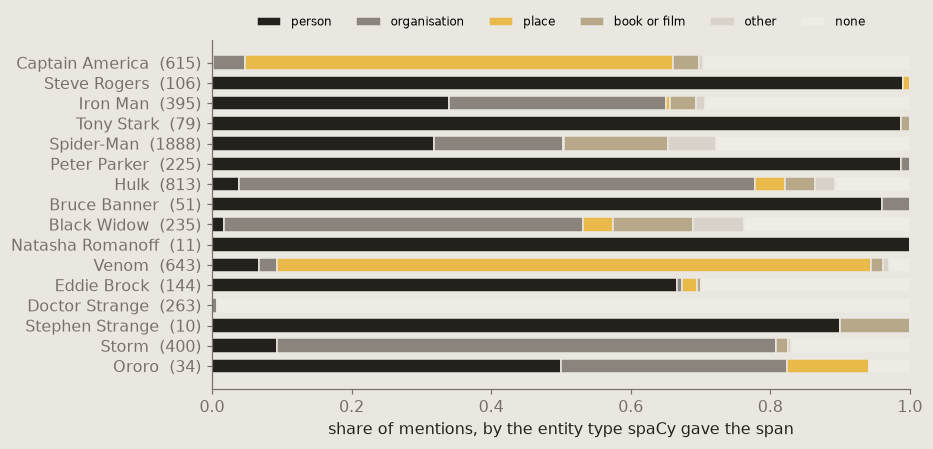

In [6]:
nlp = spacy.load("en_core_web_sm", disable=["lemmatizer"])
rows = []
for k in KEYS:
    for para, line in enumerate(l for l in pages[k].split("\n") if l.strip()):
        if len(line.split()) < 8 and not line.rstrip().endswith("."):
            continue
        for s in re.split(r"(?<=[.!?])\s+", line.strip()):
            if len(s.split()) >= 4:
                rows.append((k, para, s))
sent = pd.DataFrame(rows, columns=["page", "paragraph", "sentence"])
sent["ents"] = [[(e.start_char, e.end_char, e.text, e.label_) for e in d.ents] for d in nlp.pipe(sent.sentence, batch_size=256)]
print(f"{len(sent):,} sentences, {sent.groupby(['page', 'paragraph']).ngroups:,} paragraphs")

GROUP = {"PERSON": "person", "ORG": "organisation", "GPE": "place", "LOC": "place", "NORP": "place", "FAC": "place",
         "WORK_OF_ART": "book or film", "PRODUCT": "other", "EVENT": "other", "LAW": "other", "LANGUAGE": "other"}


def census(nm):
    pat = re.compile(r"(?<![\w-])" + re.escape(nm) + r"(?![\w-])")
    lab, pg = Counter(), set()
    for s, es, p in zip(sent.sentence, sent.ents, sent.page):
        for m in pat.finditer(s):
            pg.add(p)
            hit = [e for e in es if e[0] <= m.start() and m.end() <= e[1]]
            lab[GROUP.get(hit[0][3], "other") if hit else "none"] += 1
    return dict(name=nm, mentions=sum(lab.values()), pages=len(pg), labels=dict(lab))


PAIRS = [("Captain America", "Steve Rogers"), ("Iron Man", "Tony Stark"), ("Spider-Man", "Peter Parker"), ("Hulk", "Bruce Banner"),
         ("Black Widow", "Natasha Romanoff"), ("Venom", "Eddie Brock"), ("Doctor Strange", "Stephen Strange"), ("Storm", "Ororo")]
cen = {nm: census(nm) for pair in PAIRS for nm in pair}
share = lambda nm: cen[nm]["labels"].get("person", 0) / cen[nm]["mentions"]
display(pd.DataFrame([{"codename": a, "n": cen[a]["mentions"], "person": f"{share(a):.2f}", "real name": b, "n ": cen[b]["mentions"],
                       "person ": f"{share(b):.2f}"} for a, b in PAIRS]))
BIO_SENTS = ["Venom attacked Spider-Man in New York.", "Storm flew over Wakanda with Black Panther.", "Steve Rogers met Storm in Harlem."]
bio = [[[t.text, t.ent_iob_ + ("-" + t.ent_type_ if t.ent_type_ else "")] for t in nlp(s)] for s in BIO_SENTS]
for b in bio:
    print(" ".join(f"{w}/{t}" for w, t in b))
HAND = dict(hero_recall=0.15, person_recall=0.70, sentences=40)   # copied from SGI-7.8: 40 hand-labelled sentences, Spider-Man community
STATS["ner"] = dict(census=cen, pairs=PAIRS, bio=bio, bio_sents=BIO_SENTS, hand=HAND, sentences=len(sent),
                    cap_person=cen["Captain America"]["labels"].get("person", 0), cap_n=cen["Captain America"]["mentions"],
                    cap_place=cen["Captain America"]["labels"].get("place", 0),
                    venom_place=cen["Venom"]["labels"].get("place", 0), venom_n=cen["Venom"]["mentions"])

fig, ax = plt.subplots(figsize=(8.6, 4.2))
cats = ["person", "organisation", "place", "book or film", "other", "none"]
cols = [INK, "#8A847C", ACC, "#B7A889", "#D8D2C8", "#EFEBE5"]
labels_ = [x for pair in PAIRS for x in pair]
for i, nm in enumerate(labels_):
    left = 0
    for c, col in zip(cats, cols):
        w = cen[nm]["labels"].get(c, 0) / cen[nm]["mentions"]
        ax.barh(i, w, left=left, color=col, edgecolor=PAPER, height=0.72); left += w
ax.set_yticks(range(len(labels_)), [f"{nm}  ({cen[nm]['mentions']})" for nm in labels_]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("share of mentions, by the entity type spaCy gave the span")
ax.legend(cats, ncol=6, fontsize=8, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig(FIG / "fig1_person_share.png"); plt.show()

**Result.** spaCy finds people by their real names and loses them by their codenames. Steve Rogers is a person in
almost every mention; Captain America almost never is, and his most common type is a place: the tagger reads
*America*. Venom is a place too, and Doctor Strange is never tagged at all. Our hand labels in SGI-7.8 told the same
story on 40 sentences (recall 0.15 on hero names, 0.70 on personal names), which is why we trust the pattern here.

# Act II · Characters who aren't there, answered anyway

## 6. Captain America, everywhere and nowhere

Three of the most famous Marvel characters have no page among the 303: Captain America, Thor and Iron Man (the corpus
has *Iron Man (Ultimate Marvel character)* and *Iron Man 2020*, not the main one). They are still named in the text.
For the characters who do have a page, we check whether the number of other pages naming them tracks their hyperlink
in-degree; if it does, the mention count tells us how central the missing ones would be.

In [7]:
base = {k: re.sub(r"\s*\(.*\)$", "", name[k]) for k in KEYS}
dup = Counter(base.values())
naming = lambda nm, skip=None: sum(1 for q in KEYS if q != skip and re.search(r"(?<![\w-])" + re.escape(nm) + r"(?![\w-])", pages[q]))
mention_pages = {k: naming(base[k], k) for k in KEYS if dup[base[k]] == 1 and len(base[k]) >= 5}
indeg = dict(G.in_degree())
rho = spearmanr([indeg[k] for k in mention_pages], [mention_pages[k] for k in mention_pages]).correlation
ABSENT = ["Captain America", "Iron Man", "Thor", "Doctor Doom", "Daredevil", "Magneto", "Thanos", "Loki"]
absent = {nm: naming(nm) for nm in ABSENT}
# for the ranking, every present name counts once (shared names like Spider-Man too); "Iron Man" is excluded: that name is the missing hero's
all_present = {b: naming(b) for b in set(base.values()) if len(b) >= 5 and b != "Iron Man"}
present_rank = lambda c: 1 + sum(v > c for v in all_present.values())
above = lambda c: sorted([[b, v] for b, v in all_present.items() if v > c], key=lambda x: -x[1])
ult = "Iron_Man_(Ultimate_Marvel_character)"
print(f"{len(mention_pages)} characters with a unique name; Spearman(in-degree, pages naming) = {rho:.2f}")
display(pd.DataFrame([{"absent": nm, "pages naming": c, "rank among present": present_rank(c)} for nm, c in absent.items()]))
print(f"{name[ult]}: in-degree {indeg[ult]}, other pages saying 'Iron Man': {mention_pages[ult]}")

# 40 random mentions of "Captain America", read by us (seed 7130); the window starts 70 characters before the mention
pat = re.compile(r"(?<![\w-])Captain America(?![\w-])")
ctx = [s[max(0, m.start() - 70): m.end() + 50] for s in sent.sentence for m in pat.finditer(s)]
import random
random.seed(7130)
sample = random.sample(ctx, 40)
assert "taken the title of Captain America" in sample[0]          # the same 40 we read
for i, c in enumerate(sample):
    print(i, "|", c)

267 characters with a unique name; Spearman(in-degree, pages naming) = 0.82


,absent,pages naming,rank among present
0,Captain America,115,2
1,Iron Man,99,2
2,Thor,63,4
3,Doctor Doom,49,5
4,Daredevil,47,6
5,Magneto,34,10
6,Thanos,32,13
7,Loki,32,13


Iron Man (Ultimate Marvel character): in-degree 1, other pages saying 'Iron Man': 98
0 | asion, Black Widow worked alongside Bucky, who had taken the title of Captain America after the death of Steve Rogers.
1 | y Chapman in Captain America #18-21 (July–October 2006); in the story Captain America recruits the two heroes, who are no longer dating
2 | They go on to join Captain America's anti-registration group, the Secret Avengers.
3 | Captain America's dialogue implies that the new members, includin
4 | In the DC Comics/Marvel Comics one-shot intercompany crossover Batman/Captain America (Dec.
5 | at the 1950s Captain America was a different person from the original Captain America.
6 | Agent's suit is available as an alternate costume for Captain America in Marvel Heroes.
7 | Jeffrey Solomon Mace, also known as the Patriot and Captain America, is a superhero appearing in American comic books
8 | We got a lot of grief from the Captain America fans on that series until the fifth and six

We read the 40 mentions above and gave each one of three labels: **the character** (Steve Rogers, or the hero without
saying who), **a title** (a comic series, an issue number, a film) or **the mantle worn by someone else** (Bucky,
Sam Wilson, William Burnside, a 1940s replacement). The labels are in `MY_READING`, in the order printed.

,sentence,paragraph
Spider-Man,"degree 426, rank 1","degree 1024, rank 1"
Iron Man,"degree 150, rank 3","degree 374, rank 2"
Captain America,"degree 76, rank 17","degree 165, rank 24"
Thor,"degree 71, rank 24","degree 190, rank 17"
Wolverine,"degree 108, rank 7","degree 300, rank 3"
Storm,"degree 9, rank 649","degree 47, rank 241"
Venom,"degree 26, rank 125","degree 64, rank 132"
Black Panther,"degree 62, rank 35","degree 141, rank 38"


{'m': 8, 'c': 20, 't': 12} {'sentence': (7159, 13386), 'paragraph': (7159, 37278)}


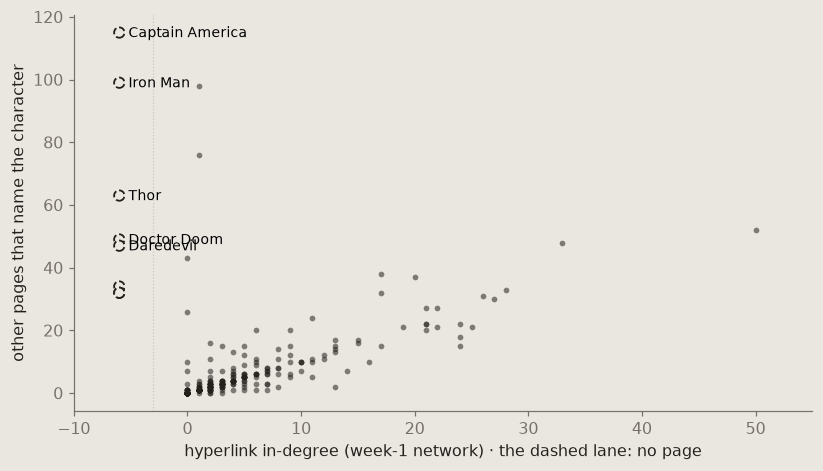

In [8]:
MY_READING = "mccctccmtc tccttcccct ctcmtmcccm ccttttcmmm"   # c character · t title · m mantle worn by someone else, mentions 0–39
reading = Counter(MY_READING.replace(" ", ""))
assert sum(reading.values()) == 40

# co-mention networks from spaCy PERSON spans: possessives stripped, "Eddie Brock / Venom" split in two, a short alias table
ALIAS = {"Steve Rogers": "Captain America", "Rogers": "Captain America", "Tony Stark": "Iron Man", "Stark": "Iron Man",
         "Thor Odinson": "Thor", "Peter Parker": "Spider-Man", "Peter": "Spider-Man", "Parker": "Spider-Man",
         "Logan": "Wolverine", "James Howlett": "Wolverine", "Bruce Banner": "Hulk", "Banner": "Hulk",
         "Natasha Romanoff": "Black Widow", "Natasha Romanova": "Black Widow", "Natasha": "Black Widow", "T'Challa": "Black Panther",
         "Ororo Munroe": "Storm", "Ororo": "Storm", "Charles Xavier": "Professor X", "Xavier": "Professor X",
         "Victor von Doom": "Doctor Doom", "Doom": "Doctor Doom", "Stephen Strange": "Doctor Strange",
         "Wade Wilson": "Deadpool", "Matt Murdock": "Daredevil", "Eddie Brock": "Eddie Brock"}
pp = []
for sid, (p, para, es) in enumerate(zip(sent.page, sent.paragraph, sent.ents)):
    for e in es:
        if e[3] == "PERSON":
            for part in re.split(r"\s*/\s*", e[2]):
                t = re.sub(r"['’]s$", "", part).strip()
                if t:
                    pp.append((sid, p, para, ALIAS.get(t, t)))
pp = pd.DataFrame(pp, columns=["sid", "page", "paragraph", "who"])


def co_mention(unit):
    g = nx.Graph()
    for grp in pp.groupby(unit).who.agg(lambda x: sorted(set(x))):
        g.add_nodes_from(grp)
        for a, b in combinations(grp, 2):
            g.add_edge(a, b, weight=g[a][b]["weight"] + 1 if g.has_edge(a, b) else 1)
    return g


WATCH = ["Spider-Man", "Iron Man", "Captain America", "Thor", "Wolverine", "Storm", "Venom", "Black Panther"]
nets = {}
for unit, key in [("sentence", "sid"), ("paragraph", ["page", "paragraph"])]:
    g = co_mention(key); deg = dict(g.degree()); order = sorted(deg, key=lambda x: (-deg[x], x))
    nets[unit] = dict(nodes=g.number_of_nodes(), edges=g.number_of_edges(),
                      watch={w: [deg.get(w, 0), order.index(w) + 1 if w in deg else None] for w in WATCH},
                      top=[[x, deg[x]] for x in order[:10]])
display(pd.DataFrame({u: {w: f"degree {d}, rank {r}" for w, (d, r) in v["watch"].items()} for u, v in nets.items()}))
STATS["absent"] = dict(rho=round(float(rho), 2), n_present=len(mention_pages), pages=absent,
                       rank={nm: present_rank(c) for nm, c in absent.items()}, above_cap=above(absent["Captain America"]),
                       above_thor=above(absent["Thor"]), cap_mentions=cen["Captain America"]["mentions"],
                       ultimate=dict(indeg=indeg[ult], naming=mention_pages[ult]), reading=dict(reading), sample=sample,
                       nets=nets, people=dict(spans=len(pp), distinct=int(pp.who.nunique())),
                       spider_pages=naming("Spider-Man", "Spider-Man"), spider_indeg=indeg["Spider-Man"],
                       scatter=[[name[k], indeg[k], mention_pages[k]] for k in mention_pages])
print(dict(reading), {u: (v["nodes"], v["edges"]) for u, v in nets.items()})

fig, ax = plt.subplots(figsize=(7.6, 4.4))
xs = np.array([indeg[k] for k in mention_pages]); ys = np.array([mention_pages[k] for k in mention_pages])
ax.scatter(xs, ys, s=14, color=INK, alpha=0.55, lw=0)
for nm, c in absent.items():
    ax.scatter([-6], [c], s=46, facecolor=PAPER, edgecolor=INK, lw=1.2, ls="--")
    if c > 40:
        ax.annotate(nm, (-6, c), xytext=(6, -3), textcoords="offset points", fontsize=9)
ax.axvline(-3, color=RULE, lw=0.8, ls=":")
ax.set_xlim(-10, max(xs) + 5); ax.set_xlabel("hyperlink in-degree (week-1 network) · the dashed lane: no page")
ax.set_ylabel("other pages that name the character")
fig.tight_layout(); fig.savefig(FIG / "fig2_named_vs_linked.png"); plt.show()

**Result.** Over the present characters, pages that name a character track its in-degree closely, so the mention
count is a fair proxy for centrality. By that proxy only Spider-Man is more central than Captain America, and Thor
comes after Spider-Man and Wolverine (*Force* also ranks above him, because it is an ordinary word as well as a page). Our reading of 40 mentions shows why a count alone misleads:
only half are the character, the rest are comic and film titles or the mantle worn by another man, and several of those
other men have pages in the corpus. Resolution brings Captain America back into the text network through *Steve
Rogers*; the corpus itself has the trap built in, with the Ultimate Iron Man page sitting under a name that dozens of
pages use for someone else.

## 7. Thor walks in

We take the current Wikipedia articles of the three missing heroes (saved in `Data/Week7/newcomers.json`; they changed
size by less than 0.3% since the corpus snapshot) and pass them through the same encoder with the same passage rule.
Nothing is retrained. Then we ask the 2D maps and BERTopic where they belong.

In [9]:
NEW = json.loads((DATA7 / "newcomers.json").read_text(encoding="utf-8"))["articles"]
NEWN = [a["title"] for a in NEW]
V = np.array([page_vec(a["text"]) for a in NEW])
newcos = []
for a, v in zip(NEW, V):
    s = E @ v; top = np.argsort(-s)[:6]
    newcos.append(dict(title=a["title"], words=a["words"], revid=a["revid"], nn=[[NAMES[j], round(float(s[j]), 3)] for j in top]))
    print(a["title"], [(NAMES[j], round(float(s[j]), 3)) for j in top])

xy_pca, new_pca = pca2.transform(E), pca2.transform(V)
tsne = lambda X: TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(X)
T0, T1 = tsne(E), tsne(np.vstack([E, V]))
assert np.allclose(T0, tsne(E))                                                  # repeats exactly


def knn(xy, k=5):
    d = np.linalg.norm(xy[:, None] - xy[None], axis=2); np.fill_diagonal(d, np.inf)
    return [set(np.argsort(r)[:k]) for r in d]


A0, A1 = knn(T0), knn(T1[:N])
kept = float(np.mean([len(a & b) / 5 for a, b in zip(A0, A1)]))
cos5 = [set([j for j in np.argsort(-S[k]) if j != k][:5]) for k in range(N)]
true0, true1 = (float(np.mean([len(a & c) / 5 for a, c in zip(A, cos5)])) for A in (A0, A1))
near = lambda XY, p, n=5: [NAMES[j] for j in np.argsort(np.linalg.norm(XY - p, axis=1))[:n]]
placement = [dict(title=t, pca=near(xy_pca, new_pca[i]), tsne=near(T1[:N], T1[N + i])) for i, t in enumerate(NEWN)]
print(f"t-SNE redraw: old pages keep {kept:.0%} of their 5 nearest dots; dots that are true cosine neighbours {true0:.2f} → {true1:.2f}")
for p in placement:
    print(p)

seen, cap_ = Counter(), Counter()
for t in texts:
    for w in re.findall(r"[A-Za-z]+", t):
        seen[w.lower()] += 1; cap_[w.lower()] += w[0].isupper()
proper = {w for w in seen if cap_[w] > seen[w] / 2}
tm = BERTopic(embedding_model=enc, umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
              vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper)), min_topic_size=10)
topics, _ = tm.fit_transform(texts, embeddings=E)
topics = np.array(topics)
new_topics, _ = tm.transform([a["text"] for a in NEW], embeddings=V)
TOPIC_WORDS = {t: [w for w, _ in tm.get_topic(t)[:4]] for t in sorted(set(topics))}
members = lambda t: [NAMES[i] for i in np.where(topics == t)[0]]
display(tm.get_topic_info()[["Topic", "Count", "Name"]])
print({t: int(x) for t, x in zip(NEWN, new_topics)})
cap_topic = int(new_topics[NEWN.index("Captain America")])
STATS["walkin"] = dict(newcomers=newcos, placement=placement, kept=round(kept, 2), true_before=round(true0, 2), true_after=round(true1, 2),
                       topics={t: int(x) for t, x in zip(NEWN, new_topics)}, topic_words={str(k): v for k, v in TOPIC_WORDS.items()},
                       topic_sizes={str(k): int(v) for k, v in Counter(topics).items()}, outliers=int((topics == -1).sum()),
                       cap_topic_pages=[n for n in members(cap_topic) if n in ("Bucky (Marvel Comics)", "U.S. Agent", "Union Jack (Marvel Comics)", "Captain Britain")])
print({k: v for k, v in STATS["walkin"].items() if k not in ("newcomers", "placement")})

Thor (Marvel Comics) [('Dargo Ktor', 0.737), ('Beta Ray Bill', 0.717), ('Thor Girl', 0.675), ('Fandral', 0.661), ('Balder the Brave', 0.65), ('Hercules (Marvel Comics)', 0.635)]
Captain America [('William Burnside (character)', 0.867), ('Nomad (Marvel Comics)', 0.778), ('Bucky (Marvel Comics)', 0.766), ('Jack Monroe (character)', 0.764), ('Isaiah Bradley', 0.739), ('Jeffrey Mace', 0.726)]
Iron Man [('War Machine', 0.829), ('Iron Man (Ultimate Marvel character)', 0.827), ('Iron Man 2020', 0.8), ('Force (comics)', 0.708), ('Detroit Steel', 0.703), ('Iron Lad', 0.674)]


t-SNE redraw: old pages keep 56% of their 5 nearest dots; dots that are true cosine neighbours 0.45 → 0.45
{'title': 'Thor (Marvel Comics)', 'pca': ['Hulk', 'The Witness (character)', 'Gauntlet (Joseph Green)', 'Black Fox (Robert Paine)', 'Ghost Rider (Danny Ketch)'], 'tsne': ['Dargo Ktor', 'Beta Ray Bill', 'Fandral', 'Thor Girl', 'Balder the Brave']}
{'title': 'Captain America', 'pca': ['Father Time (Marvel Comics)', 'Jeffrey Mace', 'Black Rider (character)', 'Happy Sam Sawyer', 'Kid Colt'], 'tsne': ['William Burnside (character)', 'Jeffrey Mace', 'Jack Monroe (character)', 'Isaiah Bradley', 'Nomad (Marvel Comics)']}
{'title': 'Iron Man', 'pca': ['Zombie (comics)', 'Man-Thing', 'Phil Urich', 'Super Rabbit', 'Solomon Kane (comics)'], 'tsne': ['War Machine', 'Iron Man (Ultimate Marvel character)', 'Iron Man 2020', 'Detroit Steel', 'Force (comics)']}


,Topic,Count,Name
0,-1,125,-1_character_series_appears_new
1,0,82,0_character_new_series_appears
2,1,41,1_symbiote_character_appears_new
3,2,32,2_new_mutant_mutants_character
4,3,23,3_character_new_costume_original


{'Thor (Marvel Comics)': -1, 'Captain America': 3, 'Iron Man': -1}
{'kept': 0.56, 'true_before': 0.45, 'true_after': 0.45, 'topics': {'Thor (Marvel Comics)': -1, 'Captain America': 3, 'Iron Man': -1}, 'topic_words': {'-1': ['character', 'series', 'appears', 'new'], '0': ['character', 'new', 'series', 'appears'], '1': ['symbiote', 'character', 'appears', 'new'], '2': ['new', 'mutant', 'mutants', 'character'], '3': ['character', 'new', 'costume', 'original']}, 'topic_sizes': {'0': 82, '-1': 125, '1': 41, '2': 32, '3': 23}, 'outliers': 125, 'cap_topic_pages': ['Bucky (Marvel Comics)', 'U.S. Agent', 'Union Jack (Marvel Comics)']}


**Result.** The encoder places the newcomers sensibly: Thor beside Beta Ray Bill, Thor Girl and the Asgardians;
Captain America beside the men who carried the shield after him; Iron Man beside War Machine. PCA can drop them onto
the old map with the old axes, and puts Thor beside pages that are nowhere in his cosine list, because two axes hold
a tenth of the variance. t-SNE has no way to add a point: it redraws, Thor lands among the right pages, and the old
pages lose a large share of their map neighbours, while their cosine neighbours did not change at all. BERTopic calls
Thor and Iron Man outliers and gives Captain America the topic of the patriotic and wartime heroes.

## 8. Ask the corpus for Thor

Sparse retrieval is week 6's TF-IDF (letters, count / length × ln(N / df), cosine). Dense retrieval is the same MiniLM
encoder over 60-word passages, each page scored by its best passage (the setting that worked best in SGI-7.10). Three
queries describe the missing heroes; the eight course presets whose page exists are the comparison.

,query,target,absent,dense_top,tfidf_top,score,rank_after,rank
0,the Norse god of thunder,Thor (Marvel Comics),True,"[Iron Man (Ultimate Marvel character), 0.68]","[Beta Ray Bill, 0.05]",0.65,"[2, 1]",NaN
1,a super soldier who carries a round shield,Captain America,True,"[Union Jack (Marvel Comics), 0.59]","[U.S. Agent, 0.06]",0.58,"[2, 1]",NaN
2,a billionaire inventor in a suit of armor,Iron Man,True,"[Turbo (comics), 0.63]","[Iron Man (Ultimate Marvel character), 0.083]",0.49,"[5, 3]",NaN
3,a hero who runs faster than sound,Quicksilver (Marvel Comics),False,"[Speed (character), 0.54]","[Thunderclap (comics), 0.053]",0.50,NaN,"[2, 11]"
4,a man who can shrink to the size of an insect,Hank Pym,False,"[Hank Pym, 0.55]","[Hank Pym, 0.061]",0.55,NaN,"[1, 1]"
5,a scientist who turns into a green giant when ...,Hulk,False,"[Hulk, 0.53]","[Hulk, 0.052]",0.53,NaN,"[1, 1]"
6,a lawyer who is also a superhero,She-Hulk,False,"[She-Hulk, 0.64]","[She-Hulk, 0.045]",0.64,NaN,"[1, 1]"
7,a short hairy Canadian with metal claws,Wolverine (character),False,"[Wolverine (character), 0.5]","[Wolverine (character), 0.089]",0.50,NaN,"[1, 1]"
8,a horse-faced alien worthy of lifting the magi...,Beta Ray Bill,False,"[Beta Ray Bill, 0.54]","[Solomon Kane (comics), 0.094]",0.54,NaN,"[1, 3]"
9,a Russian spy who became an Avenger,Black Widow (Natasha Romanova),False,"[Red Guardian, 0.61]","[Black Widow (Natasha Romanova), 0.079]",0.57,NaN,"[2, 1]"


[0.28, 0.64] {'query': 'the Norse god of thunder', 'target': 'Thor (Marvel Comics)', 'absent': True, 'dense_top': ['Iron Man (Ultimate Marvel character)', 0.68], 'tfidf_top': ['Beta Ray Bill', 0.05], 'score': 0.65, 'rank_after': [2, 1]}


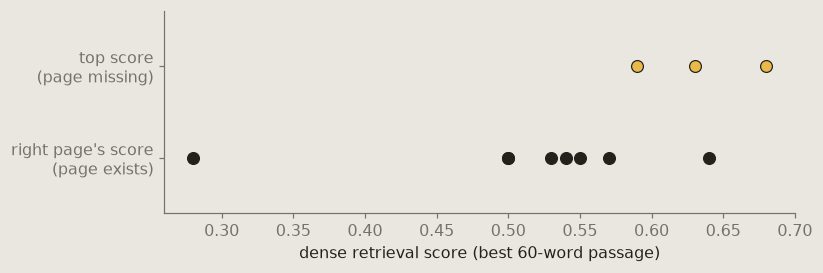

In [10]:
LETTERS = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)?")
tokens_ = lambda t: LETTERS.findall(t.lower())


def tfidf_scores(docs, query):
    cv = CountVectorizer(analyzer=tokens_); X = cv.fit_transform(docs + [query]).astype(float)
    idf = np.log(len(docs) / np.maximum((X[:-1] > 0).sum(axis=0).A1, 1))
    W = X.multiply(1 / np.maximum(X.sum(axis=1), 1)).multiply(idf).tocsr()
    n = np.sqrt(W.multiply(W).sum(axis=1)).A1; W = W.multiply(1 / np.where(n > 0, n, 1)[:, None]).tocsr()
    return (W[:-1] @ W[-1].T).toarray().ravel()


P60 = [enc.encode(passages(t, 60), normalize_embeddings=True) for t in texts]
P60new = [enc.encode(passages(a["text"], 60), normalize_embeddings=True) for a in NEW]


def dense_scores(query, pool):
    q = enc.encode(query, normalize_embeddings=True)
    return np.array([float((c @ q).max()) for c in pool])


QUERIES = [("the Norse god of thunder", "Thor (Marvel Comics)"), ("a super soldier who carries a round shield", "Captain America"),
           ("a billionaire inventor in a suit of armor", "Iron Man"),
           ("a hero who runs faster than sound", "Quicksilver (Marvel Comics)"), ("a man who can shrink to the size of an insect", "Hank Pym"),
           ("a scientist who turns into a green giant when he gets angry", "Hulk"), ("a lawyer who is also a superhero", "She-Hulk"),
           ("a short hairy Canadian with metal claws", "Wolverine (character)"),
           ("a horse-faced alien worthy of lifting the magic hammer", "Beta Ray Bill"),
           ("a Russian spy who became an Avenger", "Black Widow (Natasha Romanova)"), ("a deaf archer who never misses", "Hawkeye (comics)")]
ALLN = NAMES + NEWN
search = []
for q, target in QUERIES:
    d0, s0 = dense_scores(q, P60), tfidf_scores(texts, q)
    r = dict(query=q, target=target, absent=target in NEWN, dense_top=[NAMES[d0.argmax()], round(float(d0.max()), 2)],
             tfidf_top=[NAMES[s0.argmax()], round(float(s0.max()), 3)])
    if r["absent"]:
        d1, s1 = dense_scores(q, P60 + P60new), tfidf_scores(texts + [a["text"] for a in NEW], q)
        t = ALLN.index(target)
        r.update(score=round(float(d1[t]), 2), rank_after=[1 + int((d1 > d1[t]).sum()), 1 + int((s1 > s1[t]).sum())])
    else:
        t = NAMES.index(target)
        r.update(score=round(float(d0[t]), 2), rank=[1 + int((d0 > d0[t]).sum()), 1 + int((s0 > s0[t]).sum())])
    search.append(r)
display(pd.DataFrame(search))
present = [r["score"] for r in search if not r["absent"]]
STATS["search"] = dict(rows=search, present_range=[min(present), max(present)],
                       thor=next(r for r in search if r["target"].startswith("Thor")))
print(STATS["search"]["present_range"], STATS["search"]["thor"])

fig, ax = plt.subplots(figsize=(7.6, 2.6))
for r in search:
    y = 1 if r["absent"] else 0
    ax.scatter(r["dense_top"][1] if r["absent"] else r["score"], y, s=60, color=ACC if r["absent"] else INK,
               edgecolor=INK, lw=0.8, zorder=3)
ax.set_yticks([0, 1], ["right page's score\n(page exists)", "top score\n(page missing)"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("dense retrieval score (best 60-word passage)")
fig.tight_layout(); fig.savefig(FIG / "fig3_search_scores.png"); plt.show()

**Result.** "The Norse god of thunder" returns the Ultimate Iron Man page with a higher score than the right page gets
for any of the eight queries that have an answer. The score cannot tell a hit from a corpus that lacks the answer. A
RAG system would hand the generator that Ultimate Iron Man passage: a retrieval error, made before generation starts.
Add Thor's page and TF-IDF puts it first.

## 9. The grid, the game and the post's data

One table summarises the post: for each name, what each tool made of it. The game on top of the post and every chart
read from `STATS["viz"]`, which the post embeds; the last cell checks the embedded copy.

In [11]:
ren = {r["page"]: r for r in renames}
srow = lambda nm: next(r for r in senti if r["name"] == nm)
GRID_COLS = ["word vector", "page encoder", "sentiment", "tagger", "network", "map & clusters", "search"]
cell_ = lambda state, text: dict(state=state, text=text)
pl = {p["title"]: p for p in placement}
GRID = [
    dict(name="Storm", cells=[cell_("wrong", f"hurricane {glove_pairs['storm|hurricane']:.2f}"), cell_("right", "Emma Frost, Jean Grey"),
                               cell_("blank", "no score"), cell_("wrong", f"organisation {cen['Storm']['labels'].get('organisation', 0)}/{cen['Storm']['mentions']}"),
                               cell_("wrong", f"rank {nets['sentence']['watch']['Storm'][1]} of {nets['sentence']['nodes']:,}"), cell_("blank", "—"), cell_("blank", "—")]),
    dict(name="Black Widow", cells=[cell_("wrong", f"widow → {glove_nn['widow'][0][0]}"), cell_("wrong", f"Black Cat #{STATS['rename']['bw_cat'][0]}"),
                                     cell_("blank", f"{srow('Black Widow')['bert'][0]:+.2f}"), cell_("wrong", f"person {cen['Black Widow']['labels'].get('person', 0)}/{cen['Black Widow']['mentions']}"),
                                     cell_("blank", "—"), cell_("blank", "—"), cell_("right", "TF-IDF #1")]),
    dict(name="Venom", cells=[cell_("right", f"symbiote {glove_pairs['venom|symbiote']:.2f}"), cell_("right", "Eddie Brock"),
                               cell_("blank", f"{srow('Venom')['bert'][0]:+.2f}"), cell_("wrong", f"place {STATS['ner']['venom_place']}/{STATS['ner']['venom_n']}"),
                               cell_("right", f"degree {nets['sentence']['watch']['Venom'][0]}, via Eddie Brock / Venom"), cell_("blank", "—"), cell_("blank", "—")]),
    dict(name="Abomination", cells=[cell_("blank", "—"), cell_("blank", "—"), cell_("wrong", f"{srow('Abomination')['bert'][0]:+.2f}"),
                                     cell_("blank", "—"), cell_("blank", "—"), cell_("blank", "—"), cell_("blank", "—")]),
    dict(name="Captain America", cells=[cell_("blank", "—"), cell_("right", re.sub(r"\s*\(.*\)$", "", newcos[1]["nn"][0][0])), cell_("blank", "—"),
                                         cell_("wrong", f"place {STATS['ner']['cap_place']}/{STATS['ner']['cap_n']}"),
                                         cell_("missing", "no node"), cell_("right", f"topic {cap_topic}, with Bucky"),
                                         cell_("missing", re.sub(r"\s*\(.*\)$", "", next(r for r in search if r["target"] == "Captain America")["dense_top"][0]))]),
    dict(name="Thor", cells=[cell_("blank", "—"), cell_("right", newcos[0]["nn"][1][0]), cell_("blank", "—"), cell_("blank", "—"),
                              cell_("missing", "no node"), cell_("missing", "outlier"),
                              cell_("missing", f"Ultimate Iron Man {STATS['search']['thor']['dense_top'][1]:.2f}")]),
    dict(name="Iron Man", cells=[cell_("blank", "—"), cell_("right", newcos[2]["nn"][0][0]), cell_("blank", "—"),
                                  cell_("wrong", f"person {cen['Iron Man']['labels'].get('person', 0)}/{cen['Iron Man']['mentions']}"),
                                  cell_("missing", f"in-degree {indeg[ult]}"), cell_("missing", "outlier"),
                                  cell_("missing", re.sub(r"\s*\(.*\)$", "", next(r for r in search if r["target"] == "Iron Man")["dense_top"][0]))]),
]
display(pd.DataFrame([[c["text"] for c in r["cells"]] for r in GRID], index=[r["name"] for r in GRID], columns=GRID_COLS))

# the post's "read names as spaCy does" switch: each marked name gets the tag spaCy most often gives its mentions
LENS = [x for pair in PAIRS for x in pair] + ["Thor", "Wolverine", "Black Panther", "Black Cat", "Black Marvel", "Human Torch",
                                              "Emma Frost", "Abomination", "Ghost Rider", "Beta Ray Bill", "Thor Girl", "Bucky"]
lens = {}
for nm in LENS:
    c = cen.get(nm) or census(nm)
    if c["mentions"]:
        top, n = Counter(c["labels"]).most_common(1)[0]
        lens[nm] = [top, n, c["mentions"]]
print(lens)

# classical MDS of the eight BERT 'storm' vectors (1 − cosine), for the post's static-vs-contextual figure
D2 = (1 - C8) ** 2; J = np.eye(8) - 1 / 8
w_, v_ = np.linalg.eigh(-0.5 * J @ D2 @ J); idx = np.argsort(-w_)[:2]
storm_xy = v_[:, idx] * np.sqrt(np.maximum(w_[idx], 0))

# the opener: eight name stickers on a sheet; under each one, printed on the liner, what the machine made of the name
cen_steve = cen["Steve Rogers"]
war = next(x for x in newcos[2]["nn"] if x[0] == "War Machine")
GAME = [
    dict(name="Storm", tool="GloVe · static word vector", ghost=False, state="wrong", label="HURRICANE",
         sub=f"nearest word · {glove_pairs['storm|hurricane']:.2f}",
         q="GloVe keeps one vector for the word storm. Which word sits closest to it?",
         options=["hurricane", "x-men", "mutant", "Ororo"], answer=0,
         reveal=f"hurricane, at {glove_pairs['storm|hurricane']:.2f}. x-men is down at {glove_pairs['storm|x-men']:.2f}."),
    dict(name="Black Widow", tool="MiniLM · page encoder", ghost=False, state="wrong", label="BLACK CAT",
         sub=f"falls #{STATS['rename']['bw_cat'][0]} → #{STATS['rename']['bw_cat'][1]}",
         q="Black Widow’s page is rewritten with Natasha Romanoff in place of her codename. Which neighbour falls furthest?",
         options=["Black Cat", "Yelena Belova", "Spider-Woman (Jessica Drew)"], answer=0,
         reveal=f"Black Cat, from #{STATS['rename']['bw_cat'][0]} to #{STATS['rename']['bw_cat'][1]}. Yelena and Jessica Drew stay in the top three."),
    dict(name="Abomination", tool="DistilBERT · sentiment", ghost=False, state="wrong", label="NEGATIVE",
         sub=f"confidence {abs(srow('Abomination')['bert'][0]):.2f}",
         q="“Abomination arrived in New York.” What does the movie-review classifier say?",
         options=["positive", "negative", "it can’t tell"], answer=1,
         reveal=f"Negative, with confidence {abs(srow('Abomination')['bert'][0]):.2f}. Nothing in the sentence is negative except the name."),
    dict(name="Venom", tool="spaCy · named entities", ghost=False, state="wrong", label="PLACE", sub="tag B-GPE",
         q="“Venom attacked Spider-Man in New York.” What type does spaCy give Venom?",
         options=["person", "place", "organisation", "nothing"], answer=1, reveal="A place (GPE), like New York. Spider-Man is an organisation."),
    dict(name="Steve Rogers", tool="spaCy · the whole corpus", ghost=False, state="right", label="PERSON",
         sub=f"{cen_steve['labels']['person']} of {cen_steve['mentions']} mentions",
         q=f"Steve Rogers is named {cen_steve['mentions']} times across the corpus. In how many does spaCy tag him as a person?",
         options=["1", str(cen_steve['mentions'] // 2), str(cen_steve['labels']['person'])], answer=2,
         reveal=f"{cen_steve['labels']['person']} of {cen_steve['mentions']}. The tagger finds the man under his real name."),
    dict(name="Captain America", tool="spaCy · the whole corpus", ghost=True, state="wrong", label="PLACE",
         sub=f"person in {STATS['ner']['cap_person']} of {STATS['ner']['cap_n']}",
         q=f"Captain America has no page of his own, but {STATS['ner']['cap_n']} mentions. In how many does spaCy tag him as a person?",
         options=["1", "61", "305", "598"], answer=0,
         reveal=f"{STATS['ner']['cap_person']}. His usual tag is a place, {STATS['ner']['cap_place']} times: the tagger reads America."),
    dict(name="Iron Man", tool="BERTopic · clusters", ghost=True, state="wrong", label="OUTLIER", sub="no cluster takes him",
         q="Iron Man’s article is added to the corpus. Where does BERTopic put him?",
         options=["with the armoured heroes", "with the X-Men", "nowhere: an outlier"], answer=2,
         reveal=f"An outlier, although his nearest page, War Machine, sits at cosine {war[1]:.2f}."),
    dict(name="Thor", tool="dense retrieval", ghost=True, state="wrong", label="ULTIMATE IRON MAN",
         sub=f"top score · {STATS['search']['thor']['dense_top'][1]:.2f}",
         q="You search the corpus for “the Norse god of thunder”. What comes back first?",
         options=["Beta Ray Bill", "Hercules", "Ultimate Iron Man", "nothing"], answer=2,
         reveal=f"Ultimate Iron Man, scoring {STATS['search']['thor']['dense_top'][1]:.2f}: higher than any right answer in our test."),
]
assert STATS["walkin"]["topics"]["Iron Man"] == -1 and len(GAME) == 8

comm = sorted(nx.community.louvain_communities(U, seed=42), key=len, reverse=True)
comm_of = {k: i for i, c in enumerate(comm) for k in c}
STATS["viz"] = dict(
    names=NAMES, newcomers=NEWN, grid=dict(cols=GRID_COLS, rows=GRID), game=GAME, lens=lens,
    storm_xy=np.round(storm_xy, 3).tolist(), storm_sents=picked + WEATHER, kept=round(kept, 2), placement=placement, reading=[[c, s] for c, s in zip(MY_READING.replace(" ", ""), sample)],
    tsne0=np.round(T0, 2).tolist(), tsne1=np.round(T1, 2).tolist(), pca=np.round(np.vstack([xy_pca, new_pca]), 3).tolist(),
    comm=[comm_of[k] if len(comm[comm_of[k]]) >= 5 else -1 for k in KEYS], topics=topics.tolist(),
    nn5=[[int(j) for j in [j for j in np.argsort(-S[k]) if j != k][:5]] for k in range(N)],
    newnn=[[int(j) for j in np.argsort(-(E @ v))[:5]] for v in V],
    scatter=STATS["absent"]["scatter"], absent=absent, census={nm: cen[nm] for nm in labels_}, pairs=PAIRS,
    renames=renames, senti=senti, frames=FRAMES, storm=dict(cos=STATS["storm"]["cos"], glove=glove_nn), bio=bio, bio_sents=BIO_SENTS,
    search=search)
size = len(json.dumps(STATS["viz"], ensure_ascii=False, separators=(",", ":")))
print(f"embedded data: {size / 1e3:.0f} kB")

,word vector,page encoder,sentiment,tagger,network,map & clusters,search
Storm,hurricane 0.88,"Emma Frost, Jean Grey",no score,organisation 286/400,"rank 649 of 7,159",—,—
Black Widow,widow → wife,Black Cat #2,+1.00,person 4/235,—,—,TF-IDF #1
Venom,symbiote 0.58,Eddie Brock,+0.83,place 547/643,"degree 26, via Eddie Brock / Venom",—,—
Abomination,—,—,-0.97,—,—,—,—
Captain America,—,William Burnside,—,place 377/615,no node,"topic 3, with Bucky",Union Jack
Thor,—,Beta Ray Bill,—,—,no node,outlier,Ultimate Iron Man 0.68
Iron Man,—,War Machine,—,person 134/395,in-degree 1,outlier,Turbo


{'Captain America': ['place', 377, 615], 'Steve Rogers': ['person', 105, 106], 'Iron Man': ['person', 134, 395], 'Tony Stark': ['person', 78, 79], 'Spider-Man': ['person', 601, 1888], 'Peter Parker': ['person', 222, 225], 'Hulk': ['organisation', 601, 813], 'Bruce Banner': ['person', 49, 51], 'Black Widow': ['organisation', 121, 235], 'Natasha Romanoff': ['person', 11, 11], 'Venom': ['place', 547, 643], 'Eddie Brock': ['person', 96, 144], 'Doctor Strange': ['none', 261, 263], 'Stephen Strange': ['person', 9, 10], 'Storm': ['organisation', 286, 400], 'Ororo': ['person', 17, 34], 'Thor': ['person', 155, 327], 'Wolverine': ['organisation', 362, 674], 'Black Panther': ['organisation', 126, 280], 'Black Cat': ['place', 85, 220], 'Black Marvel': ['organisation', 35, 36], 'Human Torch': ['organisation', 143, 177], 'Emma Frost': ['person', 175, 184], 'Abomination': ['none', 109, 132], 'Ghost Rider': ['person', 247, 433], 'Beta Ray Bill': ['none', 46, 48], 'Thor Girl': ['person', 18, 26], 'Buck

## 10. Every number, pinned

`stats.json` is the single source for the post. The checks pin the headline numbers, so a change in the data, the code
or a library fails loudly instead of leaving stale prose on the site.

In [12]:
Path("stats.json").write_text(json.dumps(STATS, ensure_ascii=False, indent=1), encoding="utf-8")
EXPECT = {("storm", "across"): 0.28, ("storm", "within_page"): 0.63, ("storm", "within_weather"): 0.73,
          ("rename", "bw_cat"): [2, 19], ("rename", "cat_bw"): [1, 12], ("rename", "bp_cat"): [3, 20], ("rename", "storm_torch"): [14, 74],
          ("ner", "cap_person"): 1, ("ner", "cap_n"): 615, ("ner", "venom_place"): 547,
          ("absent", "rho"): 0.82, ("walkin", "kept"): 0.56, ("walkin", "outliers"): 125,
          ("walkin", "topics"): {"Thor (Marvel Comics)": -1, "Captain America": 3, "Iron Man": -1}}
for path, want in EXPECT.items():
    got = STATS
    for p in path: got = got[p]
    assert got == want, f"{'.'.join(path)}: expected {want}, got {got}"
assert STATS["search"]["thor"]["dense_top"] == ["Iron Man (Ultimate Marvel character)", 0.68]
assert STATS["search"]["thor"]["dense_top"][1] > STATS["search"]["present_range"][1]
assert STATS["absent"]["pages"]["Captain America"] == 115
if POST.exists():
    m = re.search(r'<script type="application/json" id="viz-data">(.*?)</script>', POST.read_text(encoding="utf-8"), re.S)
    assert m and json.loads(m.group(1)) == json.loads(json.dumps(STATS["viz"], ensure_ascii=False)), "post's embedded data is stale"
    print("post's embedded data matches STATS['viz']")
print(f"wrote stats.json ({len(STATS)} entries); all pinned numbers hold")

post's embedded data matches STATS['viz']
wrote stats.json (8 entries); all pinned numbers hold


## What we found

- **Codenames break the instruments; real names don't.** GloVe reads *storm* as weather, the page encoder treats the
  word *Black* as content, a lexicon scores *ghost* and *doom*, DistilBERT turns Abomination negative, and spaCy tags
  Captain America and Venom as places. Steve Rogers, Peter Parker and Tony Stark are people almost every time.
- **The contextual encoder is the one that reads Storm right.** BERT separates the X-Man from the weather by context.
- **The most-named characters have no page.** Captain America is named on 115 of 303 pages, second only to Spider-Man,
  and the network from weeks 1 to 4 has no node for him. Half of those mentions are the character; the
  rest are titles and other men wearing the name.
- **Every tool answers anyway.** The encoder places the newcomers well, PCA misplaces Thor, t-SNE redraws the whole map
  to fit him, BERTopic calls him an outlier, and search returns Ultimate Iron Man for the god of thunder with a higher
  score than any right answer gets.

**Choices:** GloVe 100-d, BERT base uncased, MiniLM with 180-word passages (60-word for search), DistilBERT SST-2,
VADER, spaCy `en_core_web_sm`; our weather sentences and sentence frames; the alias table above; current Wikipedia
articles for the newcomers. **Limitation:** every number comes from one run of each model on one corpus; the reading
of 40 mentions and the alias table are our own judgments.